In [29]:
from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage , AIMessage , ToolMessage
import requests

In [4]:
# tool create

@tool
def multiply(a: int, b: int) -> int:
  """Given 2 numbers a and b this tool returns their product"""
  return a * b

In [5]:
print(multiply.invoke({'a':3, 'b':4}))

12


In [43]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")

llm = ChatGroq(
    model="qwen/qwen3.8-27b",  # ✅ Yeh available hai Groq pe
    api_key=groq_api_key
)


In [44]:
response = llm.invoke("hii?")
print(response.content)

Hi there! How can I help you today?


In [45]:
llm_with_tools = llm.bind_tools([multiply])

In [46]:
llm_with_tools.invoke('hii?')

AIMessage(content='Hi there! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 290, 'total_tokens': 301, 'completion_time': 0.021064425, 'completion_tokens_details': None, 'prompt_time': 0.019899871, 'prompt_tokens_details': None, 'queue_time': 0.054766448, 'total_time': 0.040964296}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1588e-9126-7cd1-8431-1838d73f26ca-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 290, 'output_tokens': 11, 'total_tokens': 301})

In [ ]:
# human query bnai mesage mae dalnae kae liyae phir agae pass krtae rhegngae
query = HumanMessage("can you multipy 3 and 10000")

In [ ]:
# yahan llm tool btayega konsa tool use krna hae 
messages = [query]
result = llm_with_tools.invoke(messages)

In [49]:
messages.append(result)

In [50]:
response = result.tool_calls[0]
print(response)

{'name': 'multiply', 'args': {'a': 3, 'b': 10000}, 'id': '45jq26mjx', 'type': 'tool_call'}


In [53]:
# tool invoke krengae 
tool_result = multiply.invoke(result.tool_calls[0])

In [54]:
tool_result

ToolMessage(content='30000', name='multiply', tool_call_id='45jq26mjx')

In [55]:
messages.append(tool_result)

In [56]:
messages

[HumanMessage(content='can you multipy 3 and 10000', additional_kwargs={}, response_metadata={}),
 AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '45jq26mjx', 'function': {'arguments': '{"a":3,"b":10000}', 'name': 'multiply'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 300, 'total_tokens': 340, 'completion_time': 0.077722677, 'completion_tokens_details': None, 'prompt_time': 0.021726095, 'prompt_tokens_details': None, 'queue_time': 0.056180574, 'total_time': 0.099448772}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1588e-a348-7ca0-ab5a-7e0b3cd94192-0', tool_calls=[{'name': 'multiply', 'args': {'a': 3, 'b': 10000}, 'id': '45jq26mjx', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 300, 'output_tokens': 40, 'total_tokens': 340}),
 ToolMessa

In [57]:
llm_with_tools.invoke(messages).content

'3 × 10,000 = **30,000**'

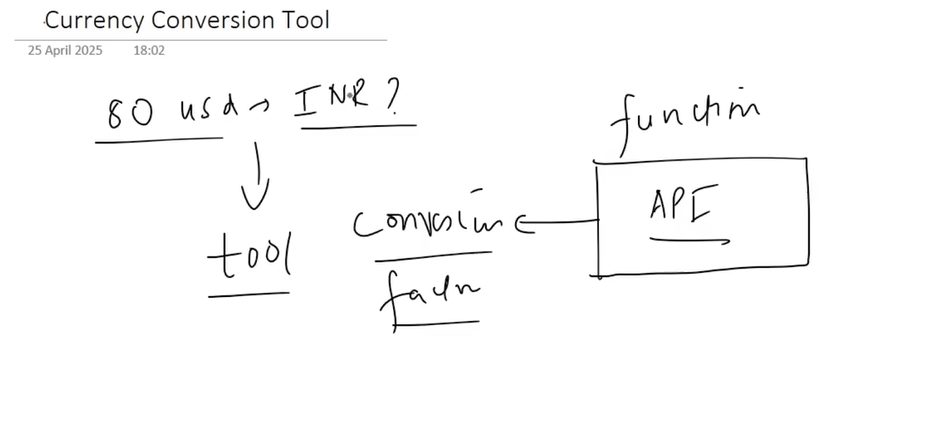

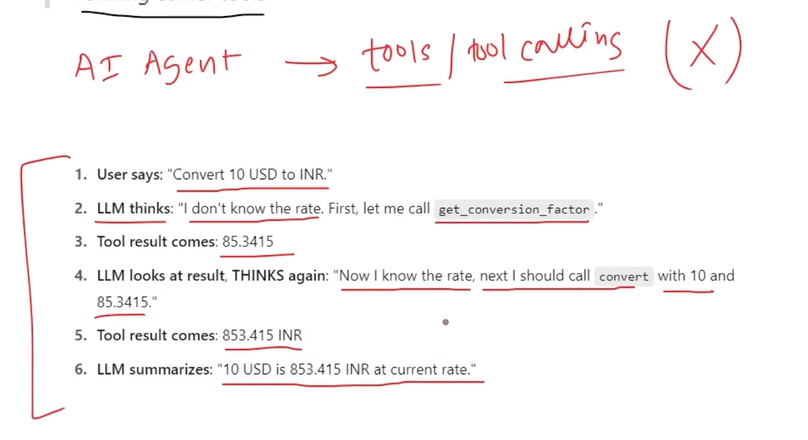

### Currency conversion tool

In [ ]:
from langchain_core.tools import InjectedToolArg
from typing import Annotated

In [59]:
@tool
def get_conversion_factor(base_currency: str, target_currency: str) -> float:
  """
  This function fetches the currency conversion factor between a given base currency and a target currency
  """
  url = f'https://v6.exchangerate-api.com/v6/c754eab14ffab33112e380ca/pair/{base_currency}/{target_currency}'

  response = requests.get(url)

  return response.json()

@tool
def convert(base_currency_value: int, conversion_rate: Annotated[float, InjectedToolArg]) -> float:
  """
  given a currency conversion rate this function calculates the target currency value from a given base currency value
  """

  return base_currency_value * conversion_rate

In [60]:
get_conversion_factor.invoke({'base_currency':'USD','target_currency':'INR'})

{'result': 'success',
 'documentation': 'https://www.exchangerate-api.com/docs',
 'terms_of_use': 'https://www.exchangerate-api.com/terms',
 'time_last_update_unix': 1792454402,
 'time_last_update_utc': 'Tue, 20 Oct 2026 00:00:02 +0000',
 'time_next_update_unix': 1792540802,
 'time_next_update_utc': 'Wed, 21 Oct 2026 00:00:02 +0000',
 'base_code': 'USD',
 'target_code': 'INR',
 'conversion_rate': 95.0564}

In [69]:
convert.invoke({'base_currency_value':10, 'conversion_rate':85.16})

851.5999999999999

In [61]:
llm_with_tools = llm.bind_tools([get_conversion_factor, convert])

In [62]:
messages = [HumanMessage('What is the conversion factor between INR and USD, and based on that can you convert 10 inr to usd')]

In [64]:
ai_message = llm_with_tools.invoke(messages)
messages.append(ai_message)

In [60]:
ai_message.tool_calls

[{'name': 'get_conversion_factor', 'args': {'base_currency': 'INR', 'target_currency': 'USD'}, 'id': 'zarh60pe3', 'type': 'tool_call'}]

In [61]:
import json

# 1. Pehle tool (get_conversion_factor) ko invoke karo
tool_call1 = ai_message.tool_calls[0]
tool_message1 = get_conversion_factor.invoke(tool_call1)

# conversion_rate nikaal lo taaki 'convert' tool mein inject kar sakein
conversion_rate = json.loads(tool_message1.content)['conversion_rate']

# messages list mein tool result add karo
messages.append(tool_message1)
print(f"Conversion Rate mil gaya: {conversion_rate}")

Conversion Rate mil gaya: 0.01052


In [62]:
# 2. Ab LLM ko invoke karo — rate milne ke baad LLM 'convert' tool call karega
ai_message2 = llm_with_tools.invoke(messages)
messages.append(ai_message2)

# Check karo tool_calls — 'convert' aa chuka hai!
ai_message2.tool_calls

[{'name': 'convert', 'args': {'base_currency_value': 10}, 'id': 'n2ch3xc9q', 'type': 'tool_call'}]

In [63]:
# 3. 'convert' tool mein conversion_rate inject karke execute karo
tool_call2 = ai_message2.tool_calls[0]
tool_call2['args']['conversion_rate'] = conversion_rate

tool_message2 = convert.invoke(tool_call2)
messages.append(tool_message2)

tool_message2

ToolMessage(content='0.1052', name='convert', tool_call_id='n2ch3xc9q')

In [64]:
# 4. Final response LLM se lo
final_response = llm_with_tools.invoke(messages)
print(final_response.content)

- **Conversion factor:** 1 INR ≈ 0.01052 USD
- **Converted amount:** 10 INR ≈ **0.1052 USD**
